### **Supervised Learning**

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [78]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_california_housing, fetch_openml, make_circles
from sklearn.impute import SimpleImputer
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import SVC, SVR

from xgboost import XGBClassifier

## Support Vector Machines (SVMs)

SVM იპოვის hyperplane-ს, რომელიც მაქსიმალურადა დაშორებული ორ კლასს შორის ყველაზე ახლოს მდებარე მონაცემებისგან (ეს მონაცემები მხარდაჭერის ვექტორებია).  
- თუ მონაცემები ხაზოვნად გაყოფადია, SVM გამოიყენებს წრფეს (2D) ან hyperplane (3D და მეტი განზომილება).  
- თუ მონაცემები არ არის ხაზოვნად გაყოფადი, SVM იყენებს კერნელურ ფუნქციებს (Kernel Trick), რათა მონაცემები უფრო მაღალი განზომილების სივრცეში გადაიყვანოს და იქ იპოვოს გაყოფის hyperplane.  

მიზანი: მაქსიმალურად გავზარდოთ Margin ჰიპერპლანსა და მხარდაჭერის ვექტორებს შორის.

<img src="../../images/svm.png" alt="supervised vs unsupervised" width=800>

1.SVM-ის მიზანი

ვიპოვოთ hyperplane:

$$w^T x + b = 0$$

რომელიც ორ კლასს (+1 და –1) სწორად ყოფს და მაქსიმალურადაა დაშორებული support vector-დან.

2. მანძილი წერტილიდან hyperplane-მდე

წერტილისათვის $x$ მანძილი hyperplane-მდე $w^T x + b = 0$ არის:

$$\text{distance} = \frac{|w^T x + b|}{\|w\|}$$

3. ნორმალიზაციის პირობა SVM-ში

Support vector-ებისთვის:

$$w^T x_i + b = \pm 1$$

ამ დროს გადაწყვეტილების საზღვარი იგივეა:

$$w^T x + b = 0$$

მაგრამ ორი პარალელური ჰიპერპლანი არსებობს:

* მარჯვენა margin: $w^T x + b = 1$
* მარცხენა margin: $w^T x + b = -1$

4. Margin-ის სიგანე

ამ ორ ჰიპერპლანს შორის მანძილი არის:

$$\text{margin} = \frac{2}{\|w\|}$$

ამიტომ:

* მეტი მარგინი = ნაკლები $\|w\|$
* მინიმუმამდე უნდა დავიყვანოთ $\|w\|^2$

5. ოპტიმიზაციის ამოცანა 

Margin-ის მაქსიმიზაცია:

$$\max \frac{2}{\|w\|}$$

ეკვივალენტურია:

$$\min \frac{1}{2}\|w\|^2$$

შეზღუდვებით:

$$y_i(w^T x_i + b) \ge 1$$


* რადგან 2 ფიქსირებულია $\max \frac{2}{\|w\|}$ ექვივალენტურია $\max\frac{1}{\|w\|}$ -ის.
* $\max\frac{1}{\|w\|}$  იგივეა რაც $\min \|w\|$
* შეგვიძლია განვიხილოთ $\|w\|^2$ , რადგან $\|w\|$ და $\|w\|^2$ მონოტონურად დაკავშირებულია, კვადრატული ტერმინი უფრო მარტივად დიფერენცირდება

ანუ:

$$
\arg\max \frac{1}{\|w\|} = \arg\min \|w\| = \arg\min \|w\|^2
$$

6. ოპტიმიზაციის პრობლემა ამოიხსნება ლაგრანჟის მეთოდით

### SVM-ის ძირითადი კონცეფციები
| მნიშვნელობა | აღწერა |
|---------------|------------|
| hyperplane | ოპტიმალური გაყოფის ხაზია, რომელიც მონაცემთა კლასებს შორის გადის |
| Support Vectors | მონაცემთა წერტილები, რომლებიც ყველაზე ახლოსაა ჰიპერპლანთან და გავლენას ახდენენ მის მდებარეობაზე |
| Margin (საზღვარი) | მანძილი ჰიპერპლანსა და უახლოეს მონაცემთა წერტილებს შორის |

---

შედეგი:  
- თუ მონაცემები კარგად გაყოფადია, SVM იპოვის საუკეთესო hyperplane-ს.  
- თუ მონაცემები არ არის ხაზოვნად გაყოფადი, შეგვიძლია გამოვიყენოთ სხვა კერნელები (RBF, Polynomial, Sigmoid).  

---

| კერნელი | როდის გამოვიყენოთ? |
|------------|------------------|
| Linear (წრფივი) | როდესაც მონაცემები იყოფ სწორი ხაზით |
| RBF (რადიალური ბაზის ფუნქცია) | როდესაც მონაცემებს აქვთ არაწრფივი საზღვრები |
| Polynomial (პოლინომიალური) | როდესაც მონაცემებს აქვთ რთული, მრუდე საზღვრები |
| Sigmoid | როდესაც მონაცემებს აქვთ S-ფორმის საზღვარი |


#### hyperplane პარამეტრები `kernel="linear"`-ის შემთხვევაში (`coef_` და `intercept_`)
- hyperplane-ის განტოლება:  

  $w_1 x + w_2 y + b = 0$

  აქედან შეგვიძლია y გამოვსახოთ:

  $y = -\frac{w_1}{w_2} x - \frac{b}{w_2}$
  
- hyperplane ვექტორი (`w`) → `model.coef_`
- hyperplane გადაკვეთის წერტილი (`b`) → `model.intercept_`

არაწრფივი ბირთვების (`kernel="rbf"`, `poly` და სხვ.) შემთხვევაში, ჰიპერპლანი არ არის სწორი ხაზი, არამედ რთული, მრუდე საზღვარი.  

#### **Penguins Dataset**

In [23]:
# Load Dataset
df_penguins = sns.load_dataset("penguins")
df_penguins = df_penguins.dropna()
df_penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


In [24]:
# მხოლოდ 2 სახეობა განვიხილოთ: Adelie and Gentoo
df_penguins_2 = df_penguins[df_penguins["species"].isin(["Adelie", "Gentoo"])]

# features and target
features = ["bill_length_mm", "bill_depth_mm"]
X = df_penguins_2[features]
y = df_penguins_2["species"]

In [25]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

SVM სწავლობს ფუნქციას:

$$
f(x) = w^T x + b
$$

* თუ $f(x) > 0$ → class 1
* თუ $f(x) < 0$ → class 0

In [26]:
# მოდელის განსაზღვრა და გაწვრთნა
svm_clf = SVC(kernel="linear", gamma="auto", C=1.0)
svm_clf.fit(X_train, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'auto'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [27]:
# პროგნოზი
y_pred = svm_clf.predict(X_test)

In [28]:
# კოეფიციენტები
w = svm_clf.coef_
b = svm_clf.intercept_
print(w.round(3), b.round(3))

[[ 0.455 -0.938]] [-4.206]


$w_{1} *$ bill_length_mm $+ w_{2} * $ bill_depth_mm $ + b = 0$

$0.455 * $ bill_length_mm $-0.938 * $ bill_depth_mm $ -4.206 = 0$

bill_depth_mm $≈ -4.48 + 0.49 * $ bill_length_mm

In [29]:
support_vectors = svm_clf.support_vectors_

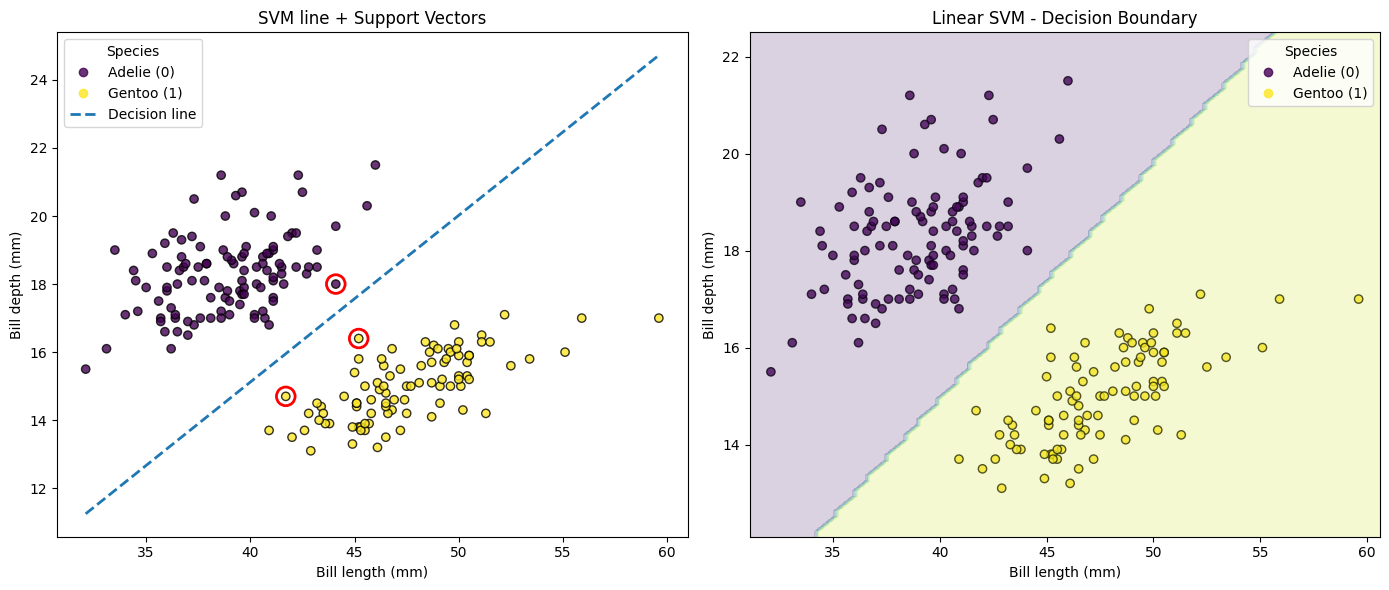

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

scatter1 = ax1.scatter(
    X_train["bill_length_mm"],
    X_train["bill_depth_mm"],
    c=y_train.astype("category").cat.codes,
    edgecolor="k",
    alpha=0.8
)

ax1.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=180,
    facecolors="none",
    edgecolors="red",
    linewidth=2,
    label="Support Vectors"
)

# Deine Linie: bill_depth_mm ≈ -4.48 + 0.49 * bill_length_mm
x_min = X_train["bill_length_mm"].min()
x_max = X_train["bill_length_mm"].max()
x_line = np.linspace(x_min, x_max, 100)
y_line = -4.48 + 0.49 * x_line

ax1.plot(x_line, y_line, linewidth=2, linestyle="--", label="Decision line")

ax1.set_xlabel("Bill length (mm)")
ax1.set_ylabel("Bill depth (mm)")
ax1.set_title("SVM line + Support Vectors")

handles1, labels1 = scatter1.legend_elements(prop="colors", alpha=0.8)
ax1.legend(handles1 + [ax1.lines[-1]], ["Adelie (0)", "Gentoo (1)", "Decision line"], title="Species")

scatter2 = ax2.scatter(
    X_train["bill_length_mm"],
    X_train["bill_depth_mm"],
    c=y_train.astype("category").cat.codes,
    edgecolor="k",
    alpha=0.8
)

DecisionBoundaryDisplay.from_estimator(
    svm_clf,
    X_train,
    response_method="predict",
    plot_method="contourf",
    alpha=0.2,
    ax=ax2
)

ax2.set_xlabel("Bill length (mm)")
ax2.set_ylabel("Bill depth (mm)")
ax2.set_title("Linear SVM - Decision Boundary")

handles2, labels2 = scatter2.legend_elements(prop="colors", alpha=0.8)
ax2.legend(handles2, ["Adelie (0)", "Gentoo (1)"], title="Species")

plt.tight_layout()
plt.show()

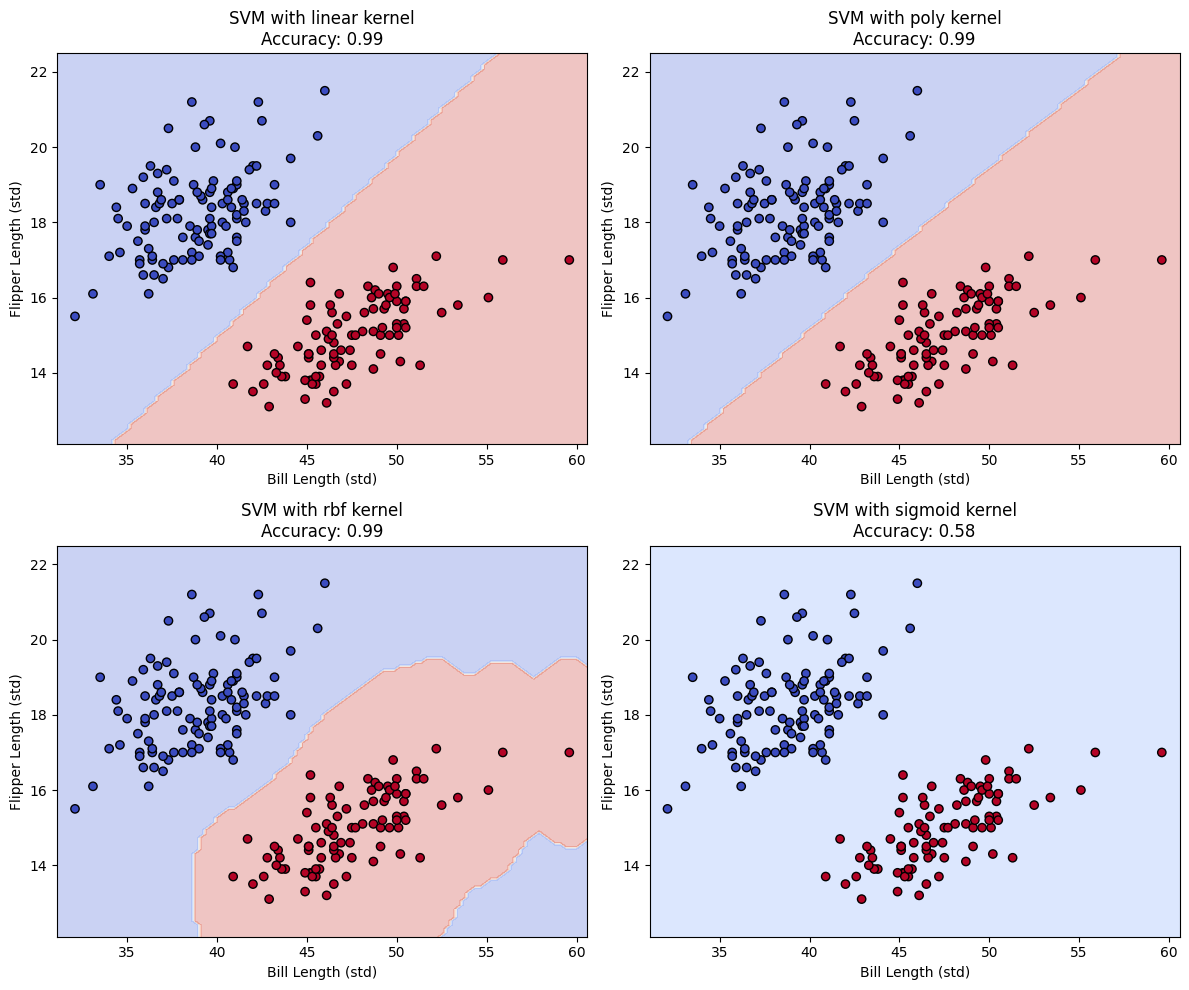

In [31]:
# Define kernels to test
kernels = ["linear", "poly", "rbf", "sigmoid"]

# Set up the plot
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, gamma="auto", C=1.0)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    disp = DecisionBoundaryDisplay.from_estimator(
        clf, X_train, ax=axes[i], response_method="predict", cmap=plt.cm.coolwarm, alpha=0.3
    )

    axes[i].scatter(X_train["bill_length_mm"], X_train["bill_depth_mm"], c=y_train.astype("category").cat.codes, cmap=plt.cm.coolwarm, edgecolors="k")
    axes[i].set_title(f"SVM with {kernel} kernel\nAccuracy: {acc:.2f}")
    axes[i].set_xlabel("Bill Length (std)")
    axes[i].set_ylabel("Flipper Length (std)")

plt.tight_layout()
plt.show()

#### Kernel

In [32]:
# სინთეტიკური მონაცემები
X, y = make_circles(
    n_samples=400,
    factor=0.3,     
    noise=0.05,    
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [33]:
# 2. Linear kernel SVM  
svm_linear = SVC(kernel="linear")
svm_linear.fit(X_train, y_train)
print("Linear kernel accuracy:", round(svm_linear.score(X_test, y_test), 2))

# 3. RBF kernel SVM 
svm_rbf = SVC(kernel="rbf", gamma="scale", C=1.0)
svm_rbf.fit(X_train, y_train)
print("RBF kernel accuracy:", svm_rbf.score(X_test, y_test))

Linear kernel accuracy: 0.66
RBF kernel accuracy: 1.0


In [34]:
def plot_decision_boundary(model, X, y, title, ax):
    # grid for background
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.2)
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k")
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

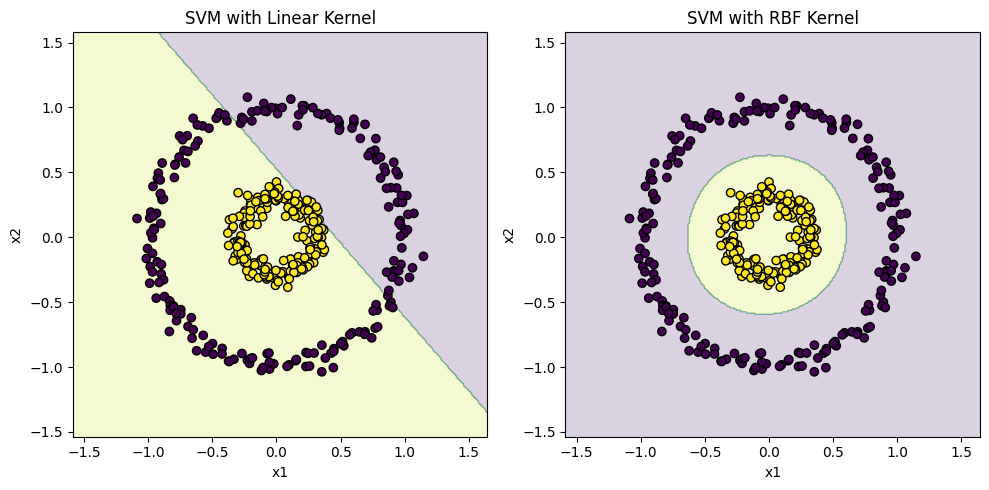

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

plot_decision_boundary(svm_linear, X, y, "SVM with Linear Kernel", axes[0])
plot_decision_boundary(svm_rbf,   X, y, "SVM with RBF Kernel",    axes[1])

plt.tight_layout()
plt.show()

#### OvR vs. OvO

In [36]:
# განვიხილოთ პინგვინის სამივე სახეობა
# features and target
X = df_penguins[features]
y = df_penguins["species"]

In [37]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

In [38]:
# Standardize features
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=features)
X_test = pd.DataFrame(scaler.transform(X_test), columns=features)

In [39]:
# SVM მოდელის გაწვრთნა (Linear Kernel)
svm_model = SVC(kernel="linear", C=1.0)  # C პარამეტრი რეგულარიზაციისთვის
svm_model.fit(X_train, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [40]:
# პროგნოზი
y_pred = svm_model.predict(X_test)

In [41]:
# მოდელის ევალუაცია, კლასიფიკაციის რეპორტი
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.95

Classification Report:
               precision    recall  f1-score   support

      Adelie       0.98      1.00      0.99        40
   Chinstrap       0.87      0.87      0.87        15
      Gentoo       0.96      0.93      0.95        29

    accuracy                           0.95        84
   macro avg       0.94      0.93      0.93        84
weighted avg       0.95      0.95      0.95        84



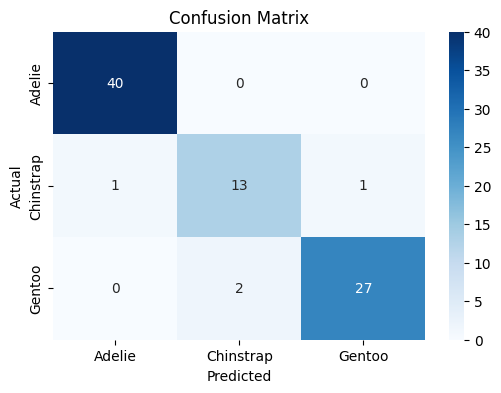

In [42]:
# Confusion Matrix 
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=svm_model.classes_, yticklabels=svm_model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [43]:
# Feature importance
feature_importance = np.abs(svm_model.coef_).mean(axis=0)  # Mean importance over classes
importance_df = pd.DataFrame({"Feature": features, "Importance": feature_importance})
importance_df = importance_df.sort_values(by="Importance", ascending=False)
importance_df

,Feature,Importance
1,bill_depth_mm,1.842121
0,bill_length_mm,1.702138


SVM ორ-ზე მეტ კლასზე მუშაობისას იყენებს რამდენიმე გადაწყვეტილების საზღვარს.  

- One-vs-Rest, OvR: თითოეულ კლასს აქვს თავისი hyperplane  
- One-vs-One, OvO: ყველა შესაძლო კლასის წყვილს აქვს საკუთარი hyperplane

მოდელის ჰიპერპარამეტრი: decision_function_shape="ovr" ("ovo")

<img src="../../images/ovr_ovn.png" alt="supervised vs unsupervised" width=700>

/Users/tsitsitepnadze/Library/Caches/pypoetry/virtualenvs/ds-playground-WjJNrmro-py3.13/lib/python3.13/site-packages/sklearn/inspection/_plot/decision_boundary.py:226: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case when the response method is 'decision_function' or 'predict_proba'.
  warnings.warn(


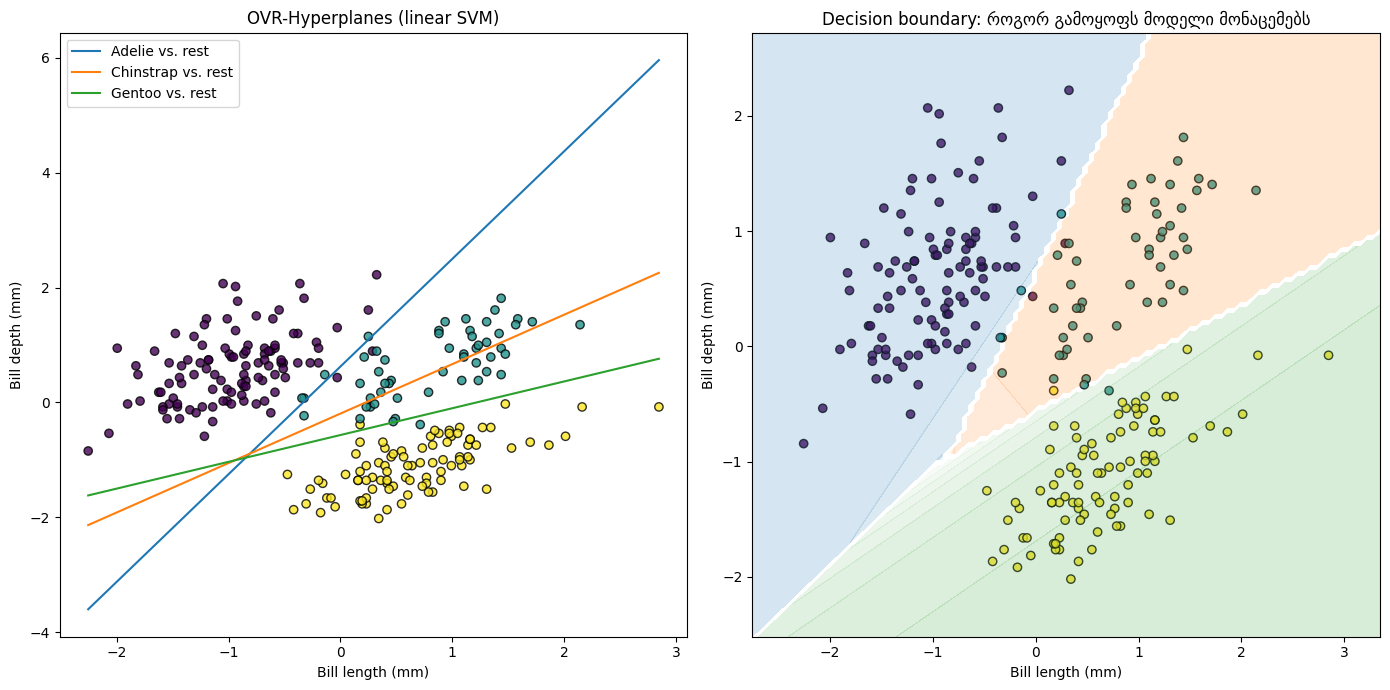

In [44]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

scatter1 = ax1.scatter(
    X_train["bill_length_mm"],
    X_train["bill_depth_mm"],
    c=y_train.astype("category").cat.codes,
    edgecolor="k",
    alpha=0.8
)

x_min = X_train["bill_length_mm"].min()
x_max = X_train["bill_length_mm"].max()
x_vals = np.linspace(x_min, x_max, 200)

for i in range(len(svm_model.classes_)):
    w_1, w_2 = svm_model.coef_[i]
    b = svm_model.intercept_[i]
    y_vals = -(w_1 / w_2) * x_vals - b / w_2
    ax1.plot(
        x_vals,
        y_vals,
        color=f"C{i}",
        label=f"{svm_model.classes_[i]} vs. rest"
    )

ax1.set_xlabel("Bill length (mm)")
ax1.set_ylabel("Bill depth (mm)")
ax1.set_title("OVR-Hyperplanes (linear SVM)")

ax1.legend()
ax1.grid(False)

scatter2 = ax2.scatter(
    X_train["bill_length_mm"],
    X_train["bill_depth_mm"],
    c=y_train.astype("category").cat.codes,
    edgecolor="k",
    alpha=0.8
)

DecisionBoundaryDisplay.from_estimator(
    svm_model,    X_train,
    cmap=plt.cm.coolwarm,
    alpha=0.2,
    ax=ax2,
    eps=0.5
)

ax2.set_xlabel("Bill length (mm)")
ax2.set_ylabel("Bill depth (mm)")
ax2.set_title("Decision boundary: როგორ გამოყოფს მოდელი მონაცემებს")

plt.tight_layout()
plt.show()

#### MNIST: ხელნაწერი ციფრების (0-9) კლასიფიკაცია. (data - 28x28 პიქსელების grayscale სურათები)

In [47]:
# Load data
df_mnist, labels = fetch_openml("mnist_784", version=1, return_X_y=True)
df_mnist.head()

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


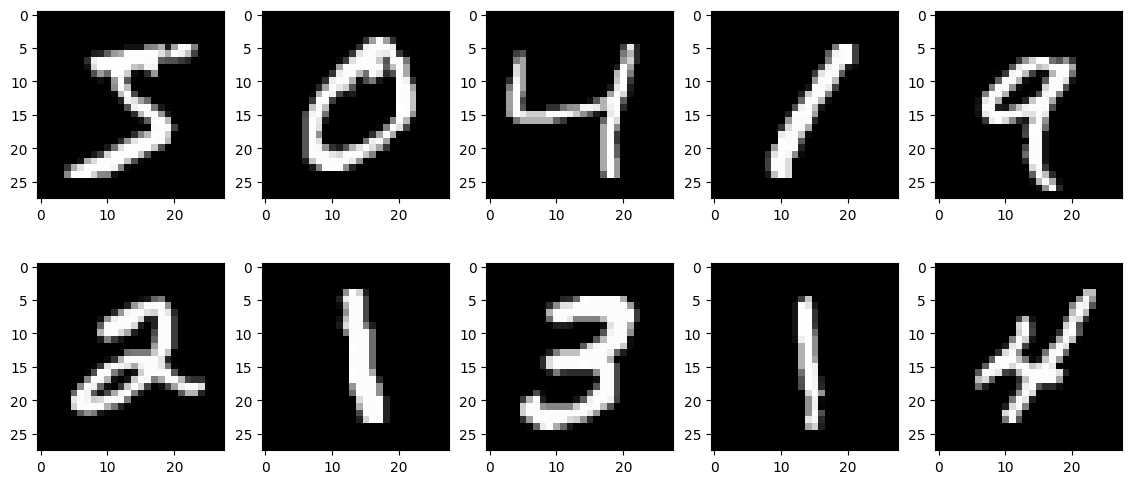

In [48]:
# დავბეჭდოთ პირველი 10 სურათი. პიქსელის მნიშვნელობების დიაპაზონი 0≤P≤255, 0 (შავი), 255 (თეთრი), შუა მნიშვნელობები (1-254) → ნაცრისფერი ელფერები
# Each row has a shape (784,) and presents 28x28 pixel grayscale images
fig=plt.figure(figsize=(14, 6))
for i in range(0,10):
    fig.add_subplot(2,5,i+1)
    plt.imshow(df_mnist.values[i].reshape(28,28), cmap="gray")
plt.show()

In [49]:
# დავყოთ მონაცემები Training and Testing Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(df_mnist, labels, test_size=0.2, random_state=42)

In [50]:
# SVM მოდელის გაწვრთნა (Using RBF Kernel for Non-Linear Decision Boundaries)
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale")  # Radial Basis Function (RBF) Kernel
svm_model.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [51]:
# პროგნოზი
y_pred = svm_model.predict(X_test)

In [52]:
# მოდელის ევალუაცია, კლასიფიკაციის რეპორტი
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.98

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      1343
           1       0.98      0.99      0.99      1600
           2       0.97      0.98      0.97      1380
           3       0.97      0.97      0.97      1433
           4       0.97      0.98      0.98      1295
           5       0.98      0.97      0.97      1273
           6       0.98      0.99      0.99      1396
           7       0.97      0.97      0.97      1503
           8       0.97      0.96      0.97      1357
           9       0.97      0.96      0.97      1420

    accuracy                           0.98     14000
   macro avg       0.98      0.98      0.98     14000
weighted avg       0.98      0.98      0.98     14000



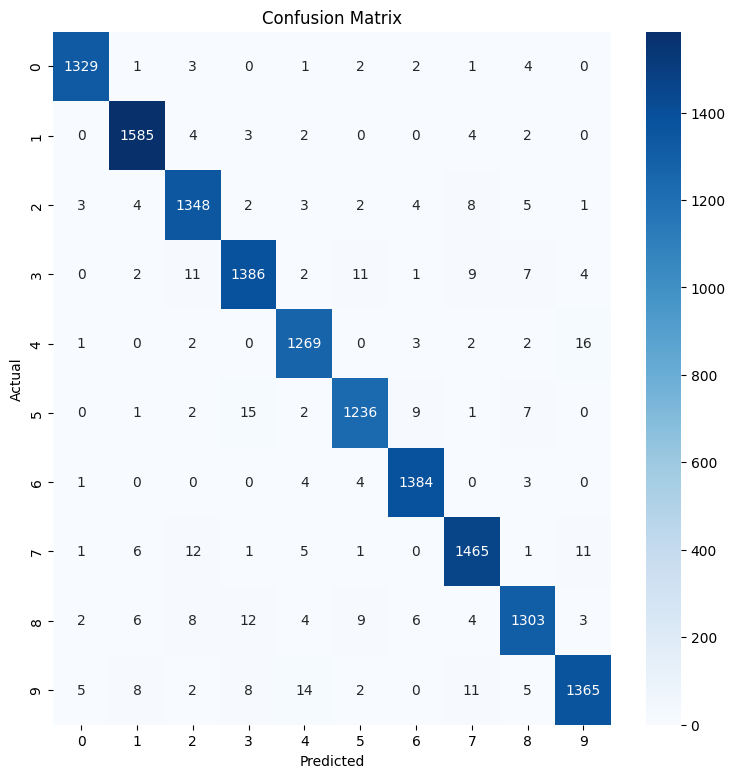

In [53]:
# Confusion Matrix 
plt.figure(figsize=(9, 9))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=svm_model.classes_, yticklabels=svm_model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

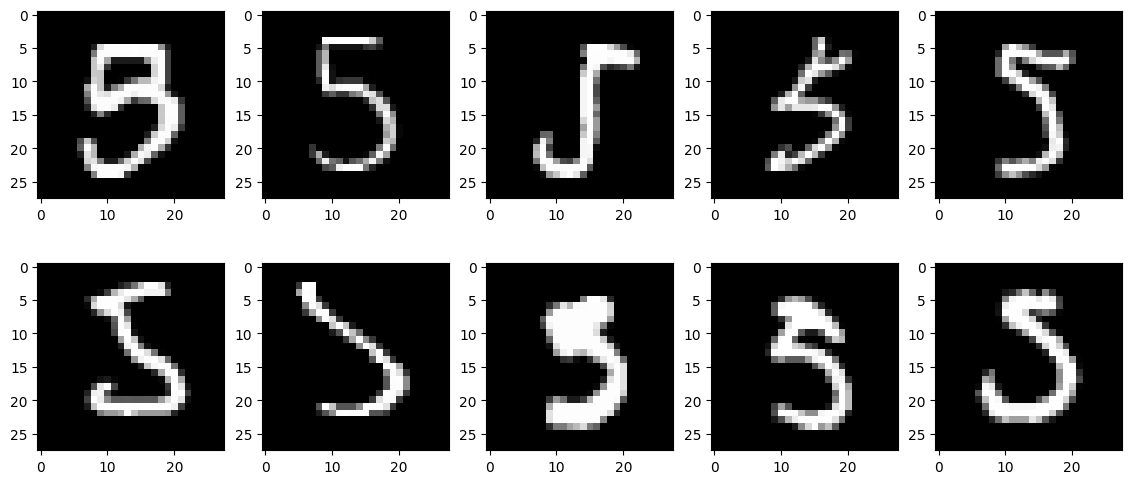

In [54]:
misclassified_3_5 = y_test[(y_pred == "3") & (y_test == "5")].index

# იმ სურათების ვიზუალიზაცია, რომელიც კლასიცირებული იქნა როგორც "3", მაგრამ სინამდვილეში არის "5"
fig=plt.figure(figsize=(14, 6))
for i in range(0,10):
    fig.add_subplot(2,5,i+1)
    plt.imshow(df_mnist.loc[misclassified_3_5].values[i].reshape(28,28), cmap="gray")
plt.show()

### SVM regression model on the California Housing Dataset 

<img src="../../images/SVR.png" alt="svr" width=600>

In [57]:
# Load the dataset
data = fetch_california_housing()
X, y = data.data, data.target
feature_names = data.feature_names

df_housing = pd.DataFrame(X, columns=feature_names)
df_housing["MedHouseVal"] = y 
df_housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [58]:
# Prepare training and test sets (80%-20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [59]:
# Standardize the data (SVM is sensitive to scale)
# StandardScaler-ს მონაცემები სტანდარტულ სკალაზე გადაყავს, ისე რომ მათი საშუალო (mean) გახდეს 0 და სტანდარტული გადახრა (standard deviation) 1, 
# რაც ეხმარება svm-ს უკეთეს აღქმაში და მახასიათებლების სწორ დამუშავებაში.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [60]:
# Train SVM Regressor (Radial Basis Function Kernel)
svr_model = SVR(kernel="rbf", C=100, gamma=0.1)
svr_model.fit(X_train, y_train)

,kernel,'rbf'
,degree,3
,gamma,0.1
,coef0,0.0
,tol,0.001
,C,100
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [61]:
# პროგნოზი
y_pred = svr_model.predict(X_test)

In [62]:
# მოდელის ევალუაცია
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}") # ერთეული - $
print(f"Mean Squared Error (MSE): {mse:.2f}") # ერთეული - $²
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}") # ერთეული - $
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 0.37
Mean Squared Error (MSE): 0.32
Root Mean Squared Error (RMSE): 0.57
R² Score: 0.75


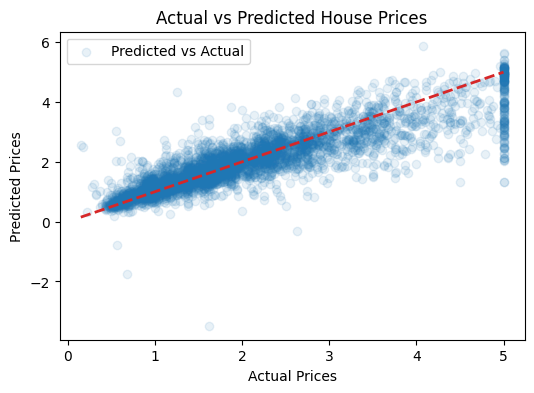

In [63]:
# Actual vs Predicted
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred, alpha=0.1, label="Predicted vs Actual")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color="C3", linestyle="dashed", linewidth=2)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.show()

| უპირატესობა                                         | უარყოფითი მხარე                                                  |
| ----------------------------------------------------------- | -------------------------------------------------------------------------- |
| ეფექტურია მაღალი განზომილებების მონაცემებზე                 | დიდ მონაცემებზე ნელა მუშაობს და მოითხოვს მეტ რესურსს          |
| კარგად მუშაობს როცა კლასები მკაფიოდ იყოფა                   | რთულია ინტერპრეტაცია     |
| Kernel-ების გამოყენებით ახორციელებს არაწრფივ კლასიფიკაციას | მგრძნობიარეა პარამეტრების (`C`, `gamma`) და Kernel-ის არჩევის მიმართ       |
| overfitting რისკი დაბალია                    | საჭიროებს მონაცემების სტანდარტიზაციას (მაგ. StandardScaler)                |
| მხოლოდ Support ვექტორები ახდენენ გავლენას გადაწყვეტილებაზე  | არ გამოაქვს კლასების ალბათობები და თუ `probability=True` მივუთითეთ, უფრო ნელია  |
-------

| სიტუაცია                            | SVM-ის გამოყენება რეკომენდებულია? |
| -------------------------------------- | --------------------------------- |
| მცირე ან საშუალო მოცულობის მონაცემები  | ✓                              |
| ბევრი მახასიათებელი, ცოტა მონაცემი       | ✓                              |
| დიდი მონაცემები (>10 000)              | - ნაკლებად მიზანშეწონილი          |
| არაწრფივი საზღვრები კლასებს შორის     | ✓ (Kernel-ით)                  |
| საჭიროა მარტივი ახსნა და ინტერპრეტაცია | - სხვა ალგორითმი სჯობს           |


### Heart Failure Prediction

#### Attribute Information
| Feature          | Description                           | Values / Unit                                                                                           |
| ---------------- | ------------------------------------- | ------------------------------------------------------------------------------------------------------- |
| `Age`            | Age of the patient                    | Years                                                                                                   |
| `Sex`            | Sex of the patient                    | `M` = Male, `F` = Female                                                                                |
| `ChestPainType`  | Type of chest pain                    | `TA` = Typical Angina, `ATA` = Atypical Angina, `NAP` = Non-Anginal Pain, `ASY` = Asymptomatic          |
| `RestingBP`      | Resting blood pressure                | mm Hg                                                                                                   |
| `Cholesterol`    | Serum cholesterol                     | mm/dl                                                                                                   |
| `FastingBS`      | Fasting blood sugar                   | `1` = FastingBS > 120 mg/dl, `0` = otherwise                                                            |
| `RestingECG`     | Resting electrocardiogram result      | `Normal` = Normal, `ST` = ST-T wave abnormality, `LVH` = probable/definite left ventricular hypertrophy |
| `MaxHR`          | Maximum heart rate achieved           | Numeric value between 60 and 202                                                                        |
| `ExerciseAngina` | Exercise-induced angina               | `Y` = Yes, `N` = No                                                                                     |
| `Oldpeak`        | ST depression value                   | Numeric value measured in depression                                                                    |
| `ST_Slope`       | Slope of the peak exercise ST segment | `Up` = upsloping, `Flat` = flat, `Down` = downsloping                                                   |
| `HeartDisease`   | Output class / target variable        | `1` = Heart disease, `0` = Normal                                                                       |


In [66]:
# Load dataset
df = pd.read_csv("../../datasets/heart_failure/heart.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [67]:
df.describe(include="object")

,Sex,ChestPainType,RestingECG,ExerciseAngina,ST_Slope
count,918,918,918,918,918
unique,2,4,3,2,3
top,M,ASY,Normal,N,Flat
freq,725,496,552,547,460


In [68]:
list(df.select_dtypes(include="number").columns)

['Age',
 'RestingBP',
 'Cholesterol',
 'FastingBS',
 'MaxHR',
 'Oldpeak',
 'HeartDisease']

In [69]:
# Preprocessing
num_features = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak", "FastingBS"]

binary_features = ["Sex", "ExerciseAngina"]
binary_categories = [["F", "M"], ["N", "Y"]] 

multi_cat_features = ["ChestPainType", "RestingECG", "ST_Slope"]

preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
        ]), num_features),

        ("bin", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("bin_enc", OrdinalEncoder(categories=binary_categories)),
        ]), binary_features),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), multi_cat_features),
    ]
)

In [70]:
# Machine Learning Pipeline
model = Pipeline([
    ("preprocess", preprocess),
    ("clf",  XGBClassifier(n_estimators=500, learning_rate=0.1, verbosity=1, random_state=42))
])

In [71]:
# Feature-Target Separation
X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [72]:
print(f"train samples: {len(X_train)}")
print(f"validation samples: {len(X_test)}")
print(f"target proportion: {sum(y_train)/len(y_train):.4f}")

train samples: 734
validation samples: 184
target proportion: 0.5531


In [73]:
# Model Training
model.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('bin', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [74]:
# Train–Test Performance Comparison 
print("Train score:", model.score(X_train, y_train))
print("Test score:", model.score(X_test, y_test))

Train score: 1.0
Test score: 0.8532608695652174


In [75]:
# Prediction
y_pred = model.predict(X_test)

In [76]:
# Classification Performance Evaluation
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.87      0.84        82
           1       0.89      0.84      0.86       102

    accuracy                           0.85       184
   macro avg       0.85      0.85      0.85       184
weighted avg       0.86      0.85      0.85       184



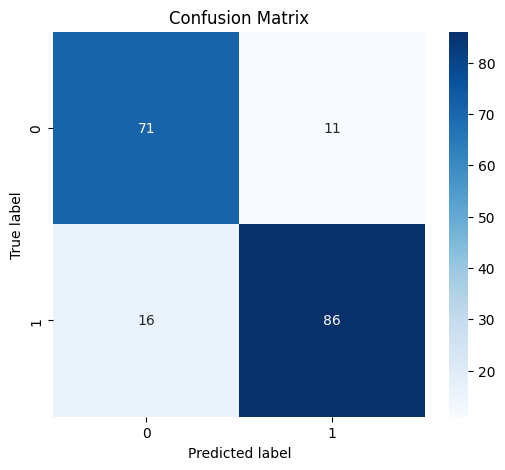

In [77]:
# Evaluation Visualization
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=model.classes_, yticklabels=model.classes_)
plt.title("Confusion Matrix")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.show()